In [ ]:
# Import the required library to upload files in Google Colab
# Run this cell, click "Choose Files", and select "Waste Management and Recycle of Indian Cities"
from google.colab import files
uploaded = files.upload()

Saving Waste_Management_India_20K.csv to Waste_Management_India_20K.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# 1. Load the dataset (Make sure the exact filename matches the uploaded file)
df = pd.read_csv("Waste_Management_India_20K.csv")

In [ ]:
# 2. Initial Overview
print("Dataset Shape:", df.shape)
display(df.head())
display(df.info())

Dataset Shape: (25203, 42)


,Record_ID,City,State,Region,City_Category,Year,Month,Season,Population,Population_Density,...,Latitude,Longitude,Air_Quality_Index,Rainfall_MM,Tourism_Impact_Score,Industrial_Activity_Level,Population_Growth_Rate,Sustainability_Index,Waste_Management_Performance_Level,Sustainability_Category
0,WM000001,Agartala,Tripura,Northeast,Tier-3,2015,1,Winter,172974,2175.5,...,23.8315,91.2868,155,23.0,4.7,1.8,3.08,33.3,Low,Poor
1,WM000002,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,27.1767,78.0081,225,16.3,10.0,8.7,1.63,43.0,Low,Average
2,WM000003,Agra,Uttar Pradesh,Central,Tier-1,2015,1,Winter,1632551,12571.9,...,27.1767,78.0081,225,16.3,10.0,8.7,1.63,43.5,Medium,Average
3,WM000004,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,23.0225,72.5714,162,8.7,6.6,4.9,1.62,42.6,High,Average
4,WM000005,Ahmedabad,Gujarat,West,Metro,2015,1,Winter,7453456,29728.0,...,23.0225,72.5714,162,8.7,6.6,4.9,1.62,49.7,High,Good


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25203 entries, 0 to 25202
Data columns (total 42 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Record_ID                           25203 non-null  object 
 1   City                                25203 non-null  object 
 2   State                               25203 non-null  object 
 3   Region                              25203 non-null  object 
 4   City_Category                       25203 non-null  object 
 5   Year                                25203 non-null  int64  
 6   Month                               25203 non-null  int64  
 7   Season                              25203 non-null  object 
 8   Population                          25203 non-null  int64  
 9   Population_Density                  25203 non-null  float64
 10  Urbanization_Rate                   25203 non-null  float64
 11  Waste_Type                          25203

None

In [ ]:
# 3. Data Cleaning & Derived Features
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

In [ ]:
# Create derived columns for deeper analysis
df['Annual_Waste_Generation_Tons'] = df['Daily_Waste_Generation_Tons'] * 365
df['Budget_Per_Ton'] = df['Waste_Management_Budget_INR'] / df['Annual_Waste_Generation_Tons']

print("Pre-processing complete. Ready for analysis.")

Pre-processing complete. Ready for analysis.


In [ ]:
# Set up the visualization layout
sns.set_theme(style="whitegrid", palette="muted")
plt.figure(figsize=(20, 25))

<Figure size 2000x2500 with 0 Axes>

<Figure size 2000x2500 with 0 Axes>

Text(0.5, 1.0, '1. Distribution of Daily Waste Generation (Tons)')

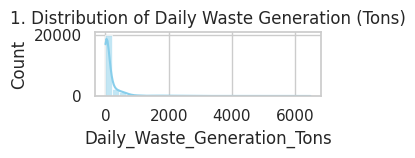

In [ ]:
# 1. Distribution of Daily Waste Generation
plt.subplot(5, 2, 1)
sns.histplot(df['Daily_Waste_Generation_Tons'], bins=30, kde=True, color='skyblue')
plt.title('1. Distribution of Daily Waste Generation (Tons)') #"Make a grid with 5 rows and 2 columns. Place the next chart in position 1." You will see this change to (5, 2, 2), (5, 2, 3), etc., for each new chart.

Text(0.5, 1.0, '2. Frequency of Waste Types Generated')

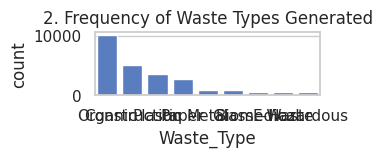

In [ ]:
# 2. Count of Waste Types
plt.subplot(5, 2, 2)
sns.countplot(data=df, x='Waste_Type', order=df['Waste_Type'].value_counts().index)
plt.title('2. Frequency of Waste Types Generated') #Simply counts how many times a category appears. (e.g., How many times does "Organic" waste show up vs. "E-Waste"?).

Text(0.5, 1.0, '3. Daily Waste Generation by City Category')

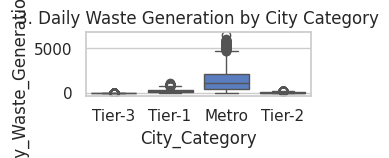

In [ ]:
# 3. Daily Waste Generation by City Category
plt.subplot(5, 2, 3)
sns.boxplot(data=df, x='City_Category', y='Daily_Waste_Generation_Tons')
plt.title('3. Daily Waste Generation by City Category')#Shows the average (the line inside the box) and the extremes (the "whiskers" outside the box). Excellent for spotting outliers in daily waste across different city types.


Text(0.5, 1.0, '4. Average Recycling Rate by Waste Type')

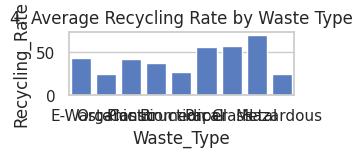

In [ ]:
# 4. Average Recycling Rate by Waste Type
plt.subplot(5, 2, 4)
sns.barplot(data=df, x='Waste_Type', y='Recycling_Rate', ci=None)
plt.title('4. Average Recycling Rate by Waste Type') #The classic bar chart. We use it to compare the average recycling rates of different waste types.

Text(0.5, 1.0, '5. Population vs. Daily Waste by Season')

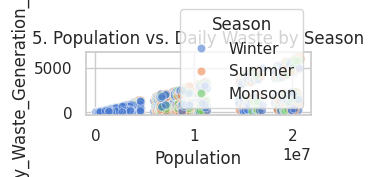

In [ ]:
# 5. Population vs. Daily Waste (Hue: Season)
plt.subplot(5, 2, 5)
sns.scatterplot(data=df, x='Population', y='Daily_Waste_Generation_Tons', hue='Season', alpha=0.6)
plt.title('5. Population vs. Daily Waste by Season')
#Places a dot for every single row of data. By plotting Population on the X-axis and Waste on the Y-axis, we can physically see if higher populations lead to more waste.

Text(0.5, 1.0, '6. Average Waste Management Budget Over Time')

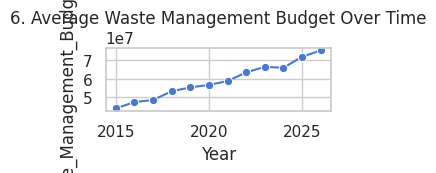

In [ ]:
# 6. Waste Management Budget over the Years
plt.subplot(5, 2, 6)
sns.lineplot(data=df, x='Year', y='Waste_Management_Budget_INR', estimator='mean', ci=None, marker='o')
plt.title('6. Average Waste Management Budget Over Time') #Connects data points over time. We use this to see if waste budgets are rising or falling year by year.

Text(0.5, 1.0, '7. Proportion of Sustainability Categories')

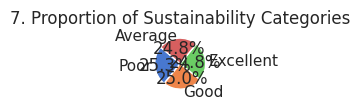

In [ ]:
# 7. Proportion of Sustainability Categories
plt.subplot(5, 2, 7)
sustainability_counts = df['Sustainability_Category'].value_counts()
plt.pie(sustainability_counts, labels=sustainability_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('7. Proportion of Sustainability Categories') #A standard pie chart to show percentages of a whole (used for Sustainability Categories).

Text(0.5, 1.0, '8. Carbon Emissions by Treatment Method')

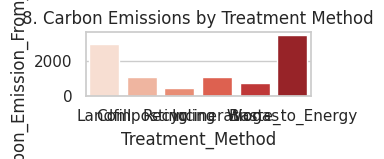

In [ ]:
# 8. Carbon Emissions by Treatment Method
plt.subplot(5, 2, 8)
sns.barplot(data=df, x='Treatment_Method', y='Carbon_Emission_From_Waste', ci=None, palette='Reds')
plt.title('8. Carbon Emissions by Treatment Method')


Text(0.5, 1.0, '9. Air Quality Index Distribution by Region')

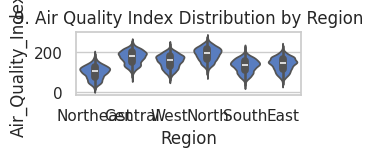

In [ ]:
# 9. Air Quality Index Distribution by Region
plt.subplot(5, 2, 9)
sns.violinplot(data=df, x='Region', y='Air_Quality_Index')
plt.title('9. Air Quality Index Distribution by Region')
#A mix between a boxplot and a histogram. It gets wider where the data is most dense. We use it to see the distribution of Air Quality across regions.

Text(0.5, 1.0, '10. Correlation Heatmap of Key Metrics')

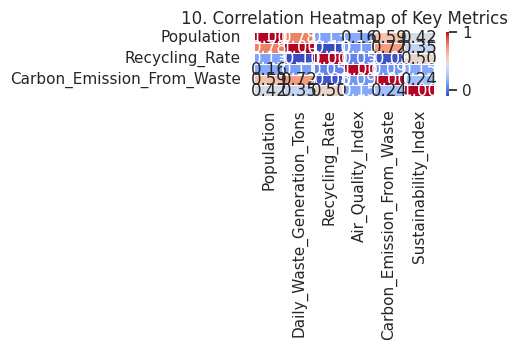

In [ ]:
# 10. Correlation Heatmap of Key Metrics
plt.subplot(5, 2, 10)
num_cols = ['Population', 'Daily_Waste_Generation_Tons', 'Recycling_Rate', 'Air_Quality_Index', 'Carbon_Emission_From_Waste', 'Sustainability_Index']
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('10. Correlation Heatmap of Key Metrics')

In [ ]:
#This calculates the mathematical relationship (correlation) between all our number columns.
#1.00 means a perfect positive link (as one goes up, the other goes up)
#-1.00 means a perfect negative link (as one goes up, the other goes down).
#The colors make it easy to spot these links instantly.

In [ ]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

#  Project Report:



**Project Name**: India Waste Management Analysis

**What We Are Doing**: Taking a large file of waste data and using Python to turn it into clean charts and useful insights.

**Why It Matter**s: It helps us see how much waste Indian cities make, how it is handled, and how it affects the environment.


  **1.Bring in the Data:** Uploading our CSV file into Google Colab so Python can read it.

  **2.Clean the Data:** Removing blank rows, fixing duplicates, and doing simple math to create new columns.

  **3.Analyze & Draw Charts:** Making 10 different types of charts using Matplotlib and Seaborn.

  4.**Find Insights**:  Writing down what the data is trying to tell us in plain English.

**Step 1 – Loading the Data (The Code Explained)**

  files.upload() creates a button on your screen so you can pick and upload your dataset from your computer into Google Colab .

  pd.read_csv() reads that file and stores it in a neat table called a DataFrame (we call it df for short). Think of it like opening an Excel spreadsheet inside Python.

**Step 2 – Cleaning the Data & Adding Math**

 dropna(): Scans the table and deletes any row that has missing or blank information so it doesn't break our math.

 drop_duplicates(): Deletes exact copycat rows so our results aren't counted twice.

 New Math Column: We multiply the daily waste by 365 to create a brand new column called Annual_Waste_Generation_Tons (yearly waste).


**Step 3 – Making the Charts (Visualizing)**

sns.set_theme() gives our charts a clean, easy-to-read white background.

figsize=(20, 25) builds a large blank canvas.

plt.subplot(5, 2, 1) acts like a grid layout. It tells Python: "Make a grid with 5 rows and 2 columns, and put this specific chart in box number 1." We repeat this to fit all 10 charts neatly in one place!

**The Pros (Merits) of Our Approach**

Beginner Friendly: The code uses simple, popular libraries (pandas, seaborn) that are easy to read and modify.

All-in-One Dashboard: Putting all 10 charts into a grid (5x2) means you don't have to scroll endlessly—everything is visible in one clean view.

Adds Value: Creating new columns (like yearly waste) shows your professor you didn't just look at the raw data—you actually built new information from it.


**The Cons (Demerits) & What to Watch Out For**

Dropping Data Can Be Risky: Using dropna() deletes an entire row even if just one unimportant cell is empty. If you aren't careful, you might throw away good data.

Crowded Charts: Packing 10 big charts onto one single canvas can make the text labels a bit small to read unless you zoom in.

Estimated Math: Multiplying daily waste by 365 assumes that every single day of the year produces the exact same amount of waste, which isn't always true in real life (e.g., festivals or holidays cause spikes)


**What Did We Discover? (Key Insights)**

Big Cities, Big Waste: Metro cities generate significantly more waste than smaller Tier-3 towns because of higher population density.

Landfills vs. Recycling: Landfills create much higher carbon emissions compared to recycling and composting.

Air Quality Link: Cities with higher air pollution (Air_Quality_Index) tend to have lower overall sustainability scores.
